# Monte Carlo Evaluation of Crop Strategies

A farmer starts with **$1000** and stakes **$10** on one crop each season. Each crop succeeds with a probability that depends on a parameter `x` between 40 and 50:

| Crop | Success probability | Payout on success |
|---|---|---|
| Corn | x% | 3x the stake |
| Wheat | x% | 3x the stake |
| Saffron | (100 - 2x)% | 10x the stake |

The notebook compares four strategies:

1. **Corn Specialist**: always plant corn with a $10 stake.
2. **Double-Down (Wheat)**: always plant wheat, and double the stake after every loss (going all in when the doubled stake is more than the balance). The stake goes back to $10 after a win.
3. **Saffron Only**: always plant saffron with a $10 stake.
4. **Chaos Method**: pick a crop uniformly at random every season.

Each strategy is simulated for 1000 seasons, 1000 times, at four values of `x`. For every combination the notebook records the mean, median and spread of the final capital, and how often the farmer ends with nothing (risk of ruin).

## Setup

In [1]:
import random
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reproducibility
RNG_SEED = 42
random.seed(RNG_SEED)
np.random.seed(RNG_SEED)

INITIAL_CAPITAL = 1000.0
BASE_STAKE = 10.0
SEASONS = 1000
RUNS = 1000
X_VALUES = [41, 44, 47, 49]

assert all(40 < x < 50 for x in X_VALUES), "x values must satisfy 40 < x < 50"


## Strategy simulators

In [2]:
@dataclass
class Probabilities:
    corn_success: float
    wheat_success: float
    saffron_success: float


def get_probabilities(x: float) -> Probabilities:
    p_cw = x / 100.0
    p_s = (100 - 2 * x) / 100.0
    return Probabilities(corn_success=p_cw, wheat_success=p_cw, saffron_success=p_s)


def play_round(balance: float, stake: float, success_prob: float, payout_multiple: float) -> float:
    if balance <= 0:
        return 0.0

    actual_stake = min(stake, balance)
    balance -= actual_stake

    if random.random() < success_prob:
        balance += payout_multiple * actual_stake

    return max(balance, 0.0)


def simulate_corn_specialist(x: float, seasons: int = SEASONS) -> tuple[float, bool]:
    p = get_probabilities(x)
    balance = INITIAL_CAPITAL
    hit_zero = False

    for _ in range(seasons):
        if balance <= 0:
            hit_zero = True
            break
        balance = play_round(balance, BASE_STAKE, p.corn_success, payout_multiple=3.0)
        if balance <= 0:
            hit_zero = True
            break

    return balance, hit_zero


def simulate_double_down_wheat(x: float, seasons: int = SEASONS) -> tuple[float, bool]:
    p = get_probabilities(x)
    balance = INITIAL_CAPITAL
    next_stake = BASE_STAKE
    hit_zero = False

    for _ in range(seasons):
        if balance <= 0:
            hit_zero = True
            break

        stake = min(next_stake, balance)  # all-in rule when required bet exceeds remaining money

        pre_round_balance = balance
        balance = play_round(balance, stake, p.wheat_success, payout_multiple=3.0)

        won = balance > (pre_round_balance - stake)
        if won:
            next_stake = BASE_STAKE
        else:
            next_stake = stake * 2

        if balance <= 0:
            hit_zero = True
            break

    return balance, hit_zero


def simulate_saffron_only(x: float, seasons: int = SEASONS) -> tuple[float, bool]:
    p = get_probabilities(x)
    balance = INITIAL_CAPITAL
    hit_zero = False

    for _ in range(seasons):
        if balance <= 0:
            hit_zero = True
            break
        balance = play_round(balance, BASE_STAKE, p.saffron_success, payout_multiple=10.0)
        if balance <= 0:
            hit_zero = True
            break

    return balance, hit_zero


def simulate_chaos_method(x: float, seasons: int = SEASONS) -> tuple[float, bool]:
    p = get_probabilities(x)
    balance = INITIAL_CAPITAL
    hit_zero = False

    crops = ["corn", "wheat", "saffron"]

    for _ in range(seasons):
        if balance <= 0:
            hit_zero = True
            break

        crop = random.choice(crops)
        if crop == "corn":
            balance = play_round(balance, BASE_STAKE, p.corn_success, payout_multiple=3.0)
        elif crop == "wheat":
            balance = play_round(balance, BASE_STAKE, p.wheat_success, payout_multiple=3.0)
        else:
            balance = play_round(balance, BASE_STAKE, p.saffron_success, payout_multiple=10.0)

        if balance <= 0:
            hit_zero = True
            break

    return balance, hit_zero


STRATEGIES = {
    "Corn Specialist": simulate_corn_specialist,
    "Double-Down (Wheat)": simulate_double_down_wheat,
    "Saffron Only": simulate_saffron_only,
    "Chaos Method": simulate_chaos_method,
}


## Running the simulations

In [3]:
records = []

for x in X_VALUES:
    for strategy_name, simulator in STRATEGIES.items():
        final_balances = []
        ruin_count = 0

        for _ in range(RUNS):
            final_balance, ruined = simulator(x, seasons=SEASONS)
            final_balances.append(final_balance)
            ruin_count += int(ruined)

        records.append(
            {
                "x": x,
                "strategy": strategy_name,
                "expected_return": float(np.mean(final_balances)),
                "median_final": float(np.median(final_balances)),
                "std_final": float(np.std(final_balances)),
                "risk_of_ruin_pct": 100.0 * ruin_count / RUNS,
            }
        )

results_df = pd.DataFrame(records)
results_df = results_df.sort_values(["x", "strategy"]).reset_index(drop=True)
results_df


,x,strategy,expected_return,median_final,std_final,risk_of_ruin_pct
0,41,Chaos Method,5196.87,5185.0,809.013290,0.0
1,41,Corn Specialist,3298.08,3300.0,444.846393,0.0
2,41,Double-Down (Wheat),6781.91,0.0,17007.745449,85.2
3,41,Saffron Only,9069.60,9100.0,1192.709453,0.0
4,44,Chaos Method,3790.21,3780.0,720.223476,0.0
5,44,Corn Specialist,4193.76,4200.0,452.569401,0.0
6,44,Double-Down (Wheat),12137.84,0.0,19159.332591,69.4
7,44,Saffron Only,2977.40,3000.0,1076.507891,1.4
8,47,Chaos Method,2394.41,2390.0,595.885435,0.0
9,47,Corn Specialist,5079.66,5070.0,474.300205,0.0


In [4]:
summary = results_df[["x", "strategy", "expected_return", "risk_of_ruin_pct", "median_final", "std_final"]].copy()
summary["expected_return"] = summary["expected_return"].round(2)
summary["risk_of_ruin_pct"] = summary["risk_of_ruin_pct"].round(2)
summary["median_final"] = summary["median_final"].round(2)
summary["std_final"] = summary["std_final"].round(2)
summary


,x,strategy,expected_return,risk_of_ruin_pct,median_final,std_final
0,41,Chaos Method,5196.87,0.0,5185.0,809.01
1,41,Corn Specialist,3298.08,0.0,3300.0,444.85
2,41,Double-Down (Wheat),6781.91,85.2,0.0,17007.75
3,41,Saffron Only,9069.60,0.0,9100.0,1192.71
4,44,Chaos Method,3790.21,0.0,3780.0,720.22
5,44,Corn Specialist,4193.76,0.0,4200.0,452.57
6,44,Double-Down (Wheat),12137.84,69.4,0.0,19159.33
7,44,Saffron Only,2977.40,1.4,3000.0,1076.51
8,47,Chaos Method,2394.41,0.0,2390.0,595.89
9,47,Corn Specialist,5079.66,0.0,5070.0,474.30


## Expected capital and risk of ruin

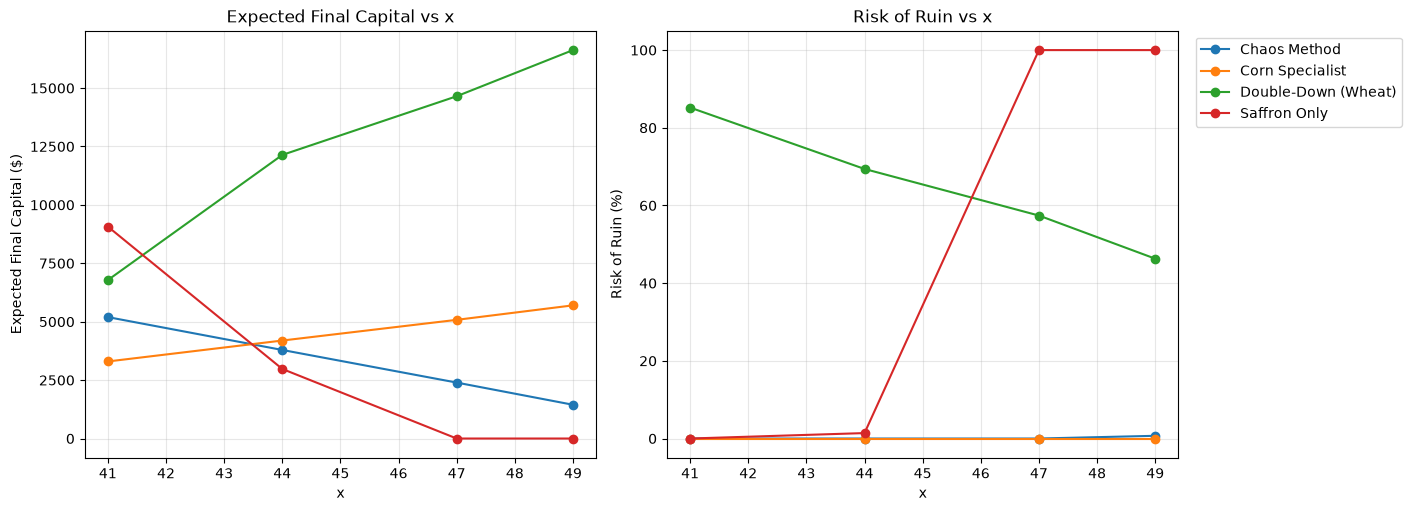

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

for strategy in results_df["strategy"].unique():
    temp = results_df[results_df["strategy"] == strategy]
    axes[0].plot(temp["x"], temp["expected_return"], marker="o", label=strategy)
    axes[1].plot(temp["x"], temp["risk_of_ruin_pct"], marker="o", label=strategy)

axes[0].set_title("Expected Final Capital vs x")
axes[0].set_xlabel("x")
axes[0].set_ylabel("Expected Final Capital ($)")
axes[0].grid(alpha=0.3)

axes[1].set_title("Risk of Ruin vs x")
axes[1].set_xlabel("x")
axes[1].set_ylabel("Risk of Ruin (%)")
axes[1].grid(alpha=0.3)

axes[1].legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
plt.show()


## Final capital for runs that did not go broke

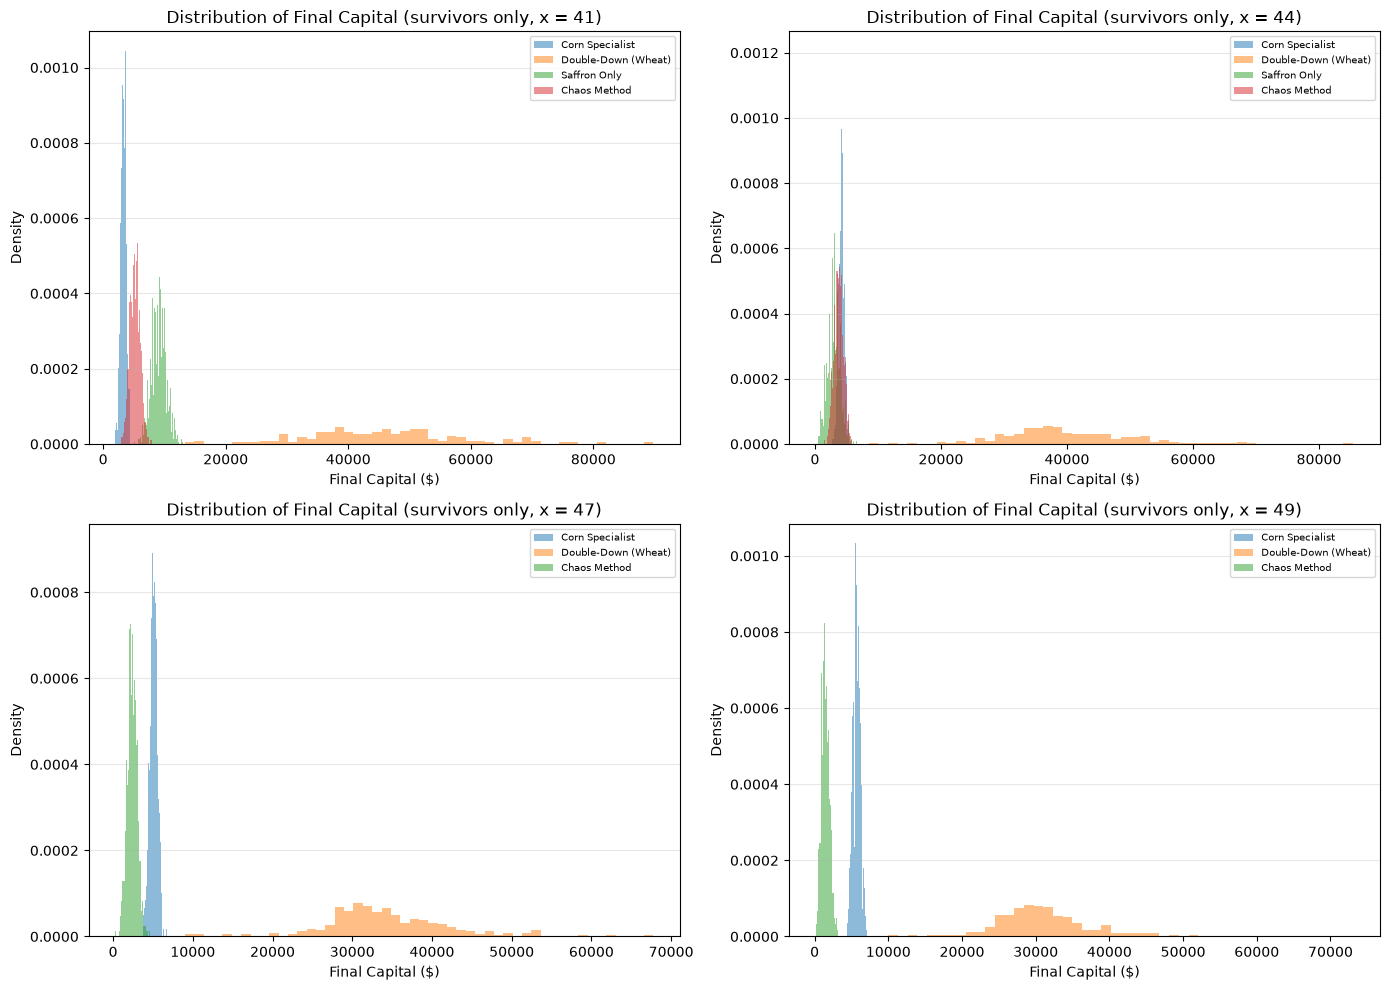

In [6]:
import collections
raw_results = collections.defaultdict(lambda: collections.defaultdict(list))

random.seed(RNG_SEED)
np.random.seed(RNG_SEED)

for x in X_VALUES:
    for strategy_name, simulator in STRATEGIES.items():
        for _ in range(RUNS):
            final_balance, _ = simulator(x, seasons=SEASONS)
            raw_results[x][strategy_name].append(final_balance)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, x in enumerate(X_VALUES):
    ax = axes[idx]
    for name in STRATEGIES:
        res = np.array(raw_results[x][name])
        nonzero = res[res > 0]
        if len(nonzero) > 0:
            ax.hist(nonzero, bins=50, alpha=0.5, label=name, density=True)
    ax.set_title(f"Distribution of Final Capital (survivors only, x = {x})")
    ax.set_xlabel("Final Capital ($)")
    ax.set_ylabel("Density")
    ax.legend(fontsize=7)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


## Expected value of a single $10 bet

In [7]:
print(f"{'x':>3} | {'EV Corn ($)':<14} | {'EV Wheat ($)':<14} | {'EV Saffron ($)':<14}")
print("_" * 55)
for x in X_VALUES:
    p_c = x / 100
    p_s = (100 - 2 * x) / 100
    ev_corn    = p_c * 3 * BASE_STAKE - BASE_STAKE
    ev_wheat   = p_c * 3 * BASE_STAKE - BASE_STAKE
    ev_saffron = p_s * 10 * BASE_STAKE - BASE_STAKE
    print(f"{x:>3} | {ev_corn:<14.2f} | {ev_wheat:<14.2f} | {ev_saffron:<14.2f}")


  x | EV Corn ($)    | EV Wheat ($)   | EV Saffron ($)
_______________________________________________________
 41 | 2.30           | 2.30           | 8.00          
 44 | 3.20           | 3.20           | 2.00          
 47 | 4.10           | 4.10           | -4.00         
 49 | 4.70           | 4.70           | -8.00         


## Ranking for a risk-averse farmer

In [8]:
risk_averse_ranking = (
    results_df.groupby("strategy", as_index=False)
    .agg(avg_ruin=("risk_of_ruin_pct", "mean"), avg_expected_return=("expected_return", "mean"))
    .sort_values(["avg_ruin", "avg_expected_return"], ascending=[True, False])
)

best_risk_averse = risk_averse_ranking.iloc[0]

print("Risk-averse ranking (lowest ruin first):")
display(risk_averse_ranking.round(2))

print(
    f"Best strategy for a risk-averse farmer: {best_risk_averse['strategy']} "
    f"(lowest average ruin = {best_risk_averse['avg_ruin']:.2f}%)."
)


Risk-averse ranking (lowest ruin first):


,strategy,avg_ruin,avg_expected_return
1,Corn Specialist,0.00,4567.79
0,Chaos Method,0.18,3206.60
3,Saffron Only,50.35,3011.75
2,Double-Down (Wheat),64.58,12548.84


Best strategy for a risk-averse farmer: Corn Specialist (lowest average ruin = 0.00%).


## Analysis

### Expected value of one bet

For a $10 stake:

- **Corn and wheat:** `EV = 0.3x - 10`. This is positive for every `x` above 33.3, so it's positive across the whole tested range: +$2.30 at `x = 41`, rising to +$4.70 at `x = 49`.
- **Saffron:** `EV = 10 * (100 - 2x)% * 10 - 10 = 90 - 2x`. This is positive only below `x = 45`: +$8.00 at `x = 41`, then -$8.00 at `x = 49`. As `x` grows, saffron's success chance falls twice as fast as corn's rises.
- **Chaos (uniform mix):** `EV = (70 - 1.4x) / 3`. This stays positive for every `x` below 50, but it shrinks towards zero as saffron gets worse.

### Expected return

- **Saffron Only** has the best mean at `x = 41` ($9,070), because each saffron bet is worth more than a corn bet there. Once its EV turns negative it falls apart, and it ends at $0 in every run at `x = 47` and `x = 49`.
- **Corn Specialist** grows steadily with `x`, from $3,298 to $5,700. Its spread is the tightest of the four (standard deviation around $450).
- **Chaos Method** tracks the blended EV. It beats Corn at `x = 41` ($5,197 vs $3,298), but falls behind from `x = 44` onwards as the saffron seasons start losing money.
- **Double-Down (Wheat)** has the highest mean at every `x` (up to $16,625), but the median tells a different story.

### Risk of ruin

| Strategy | x = 41 | x = 44 | x = 47 | x = 49 |
|---|---|---|---|---|
| Corn Specialist | 0% | 0% | 0% | 0% |
| Chaos Method | 0% | 0% | 0% | 0.7% |
| Saffron Only | 0% | 1.4% | 100% | 100% |
| Double-Down (Wheat) | 85.2% | 69.4% | 57.4% | 46.3% |

Double-Down's median final capital is **$0** for `x = 41`, `44` and `47`, so most farmers using it go broke. A few runs that never hit a long losing streak pull the mean up. The doubling is what kills it: after 7 losses in a row the stake is $1,280, which is more than the farmer usually has, so one more loss ends the run.

### Best strategy for a risk-averse farmer

**Corn Specialist.** It never went broke in any of the 4,000 runs. The stake is fixed at $10, so a single season can lose at most $10, and the farmer would need about 100 more losses than wins to lose the $1,000. With a positive EV on every bet, its balance grows steadily and predictably. Double-Down has a higher mean, but a farmer who cares about the typical outcome rather than the lucky few should avoid it.

Saffron Only and Chaos beat Corn at low `x`, but both depend on saffron, and saffron stops paying off once `x` reaches 45. If `x` isn't known in advance, Corn is the only strategy that does well across the whole range.

The random seed is fixed (`RNG_SEED = 42`), so re-running the notebook gives the same numbers.